In [1]:
# Assignment 3: GAN on MNIST

In [2]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print(os.getcwd())

/Users/Aditi_1/Documents/Columbia - Fall 2026/Applied Gen AI/genai


In [3]:
import torch
import torch.nn as nn

from helper_lib.data_loader import get_mnist_loader
from helper_lib.generator import generate_samples
from helper_lib.model import get_model
from helper_lib.trainer import train_gan
from helper_lib.utils import get_device

torch.manual_seed(42)
device = get_device()
print(f"Using device: {device}")

Using device: mps


In [4]:
gan = get_model("GAN")
z = torch.randn(4, 100)
fake = gan.generator(z)
print("Generator out:", fake.shape)                        # [4, 1, 28, 28]
print("Discriminator out:", gan.discriminator(fake).shape)  # [4, 1]
print(gan)

Generator out: torch.Size([4, 1, 28, 28])
Discriminator out: torch.Size([4, 1])
GAN(
  (generator): Generator(
    (fc): Linear(in_features=100, out_features=6272, bias=True)
    (deconv1): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (deconv2): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
  (discriminator): Discriminator(
    (conv1): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (conv2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (flatten): Flatten(start_dim=1, end_dim=-1)
    (fc): Linear(in_features=6272, out_features=1, bias=True)
  )
)


In [5]:
loader = get_mnist_loader("data", batch_size=128)
criterion = nn.BCELoss()
opt_g = torch.optim.Adam(gan.generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(gan.discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

gan = train_gan(gan, loader, criterion, (opt_g, opt_d), device=device, epochs=10)

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 2.80MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.87MB/s]
Epoch 1/10: 100%|███████████████████████████████████████| 468/468 [00:27<00:00, 17.26it/s, D loss=0.3502, G loss=1.3815]


Epoch 1: D loss=0.2489, G loss=2.5343


Epoch 2/10: 100%|███████████████████████████████████████| 468/468 [00:23<00:00, 19.82it/s, D loss=0.3108, G loss=3.2848]


Epoch 2: D loss=0.2236, G loss=2.1091


Epoch 3/10: 100%|███████████████████████████████████████| 468/468 [00:23<00:00, 19.69it/s, D loss=0.2952, G loss=2.0771]


...

Epoch 8: D loss=0.6838, G loss=4.9123


Epoch 9/10: 100%|███████████████████████████████████████| 468/468 [00:24<00:00, 19.08it/s, D loss=0.3096, G loss=3.2987]


Epoch 9: D loss=0.3218, G loss=2.3945


Epoch 10/10: 100%|██████████████████████████████████████| 468/468 [00:23<00:00, 19.87it/s, D loss=0.3143, G loss=3.1422]

Epoch 10: D loss=0.2958, G loss=2.5816


Matplotlib is building the font cache; this may take a moment.


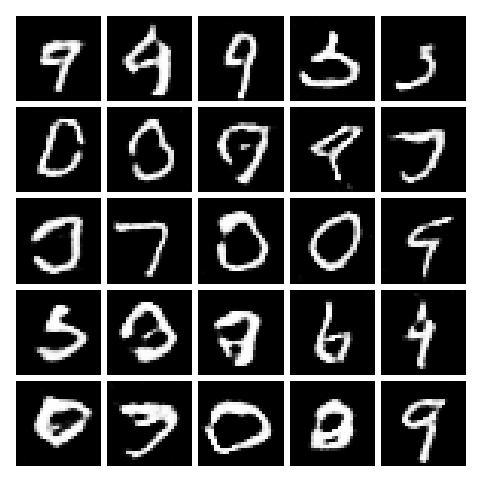

In [6]:
generate_samples(gan, device, num_samples=25)

In [7]:
os.makedirs("app/models", exist_ok=True)
torch.save(gan.generator.cpu().state_dict(), "app/models/gan_mnist_generator.pth")
print("Saved app/models/gan_mnist_generator.pth")

Saved app/models/gan_mnist_generator.pth
